(normalization-and-quality)=
# Normalization, filtering and sample quality

Check the samples, genes and libraries of a cube before testing them. By default {api}`limma_voom` leaves out the samples of fewer than 10 cells in each cell type, keeps the genes that edgeR's filter passes with the design, and scales the libraries by TMM factors. This page takes these steps one at a time, with the figures that show whether the samples group as the design expects and whether a sample or gene behaves unlike the rest, so that each choice can rest on what the data show. It uses the CD14+ monocytes of the Kang data [@kang2018] and the simulated bulk experiment, whose noisier sample is known (the `kang2018` and `simulated_bulk` datasets of the [Datasets](../reference/datasets.md) page). [Normalization and filtering](../statistics/normalization_and_filtering.md) explains each step.

## Do the samples group as expected?

limma's multidimensional scaling plot ({api}`plot_mds`) places the samples of one cell type so that their distances are the typical log2 fold changes between them ([Samples at a glance](../statistics/normalization_and_filtering.md#samples-at-a-glance) says how it prepares a cube's counts).


CytePool 0.1.dev70+g194507939


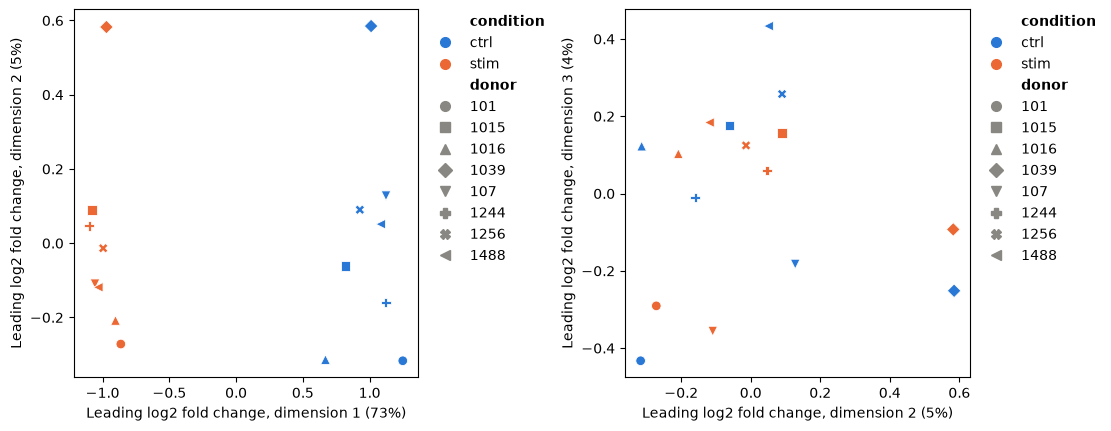

In [1]:
import matplotlib.pyplot as plt
import numpy as np

import cytepool
from cytepool import Design, limma_voom, principal_components, read_cube
from cytepool.normalization import (
    filter_by_expression,
    median_ratio_size_factors,
    rle_factors,
    tmm_factors,
    upper_quartile_factors,
)
from cytepool.plotting import (
    plot_mds,
    plot_mean_variance,
    plot_pca,
    plot_residual_variances,
    plot_sample_weights,
)
from cytepool.stats.voom import voom

kang = read_cube("kang2018.cube.zarr")
print(f"CytePool {cytepool.__version__}")
figure, (left, right) = plt.subplots(1, 2, figsize=(11, 4.2), layout="constrained")
for ax, dimensions in ((left, (1, 2)), (right, (2, 3))):
    plot_mds(
        kang,
        group="CD14+ Monocytes",
        color_by="condition",
        marker_by="donor",
        dimensions=dimensions,
        ax=ax,
    )
plt.show()

The first dimension, nearly three quarters of the variation, is the stimulation. The next ones are the donors: the two samples of each donor lie near each other, and donor 1039 stands apart from the rest. Differences between donors are why the design pairs each donor's samples ([Genes that change in each cell type](genes_per_cell_type.ipynb)). A sample far from its group on such a plot deserves a look before any test.

DESeq2's PCA plot ({api}`plot_pca`) places the same samples on the principal components of their most variable genes, each labelled with its share of the variance [@love2014]. {api}`principal_components` also returns the loadings of the genes, which say what each component is made of.


PC1, the largest loadings: ISG15, IL1RN, IDO1, IFITM3, MX1, APOBEC3A, LY6E, TNFSF13B
PC2, the largest loadings: HBB, FUCA1, SNCA, NDUFA12, CD52, IL1B, CCL3, CCL4


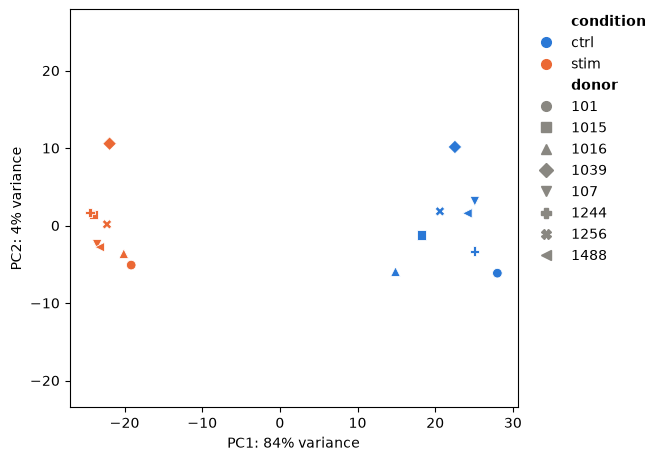

In [2]:
pca = principal_components(kang, group="CD14+ Monocytes")
symbols = pca.features["symbol"]
for component in (0, 1):
    largest = np.argsort(-np.abs(pca.loadings[:, component]))[:8]
    print(f"PC{component + 1}, the largest loadings:", ", ".join(symbols[largest]))
plot_pca(pca, color_by="condition", marker_by="donor")
plt.show()

The first component, 84% of the variance, is the stimulation again, and the genes with the largest loadings on it are interferon-stimulated genes such as ISG15, MX1 and IFITM3. The second sets the two samples of donor 1039 apart, as the second dimension of the MDS plot does, and the gene with by far the largest loading on it is HBB, whose reads come from red cells that contaminate some samples more than others; the genes with outlying variances, below, return to it. The two plots agree here, although they measure the distances between samples differently.

## Which genes to test

voom's plot ({api}`plot_mean_variance`) shows how the variance of the log counts falls with their level, the trend from which voom weights every observation [@law2014]. Genes with too few counts bend the trend down at its low end, where voom would then weight noisy observations most ([Filtering by expression](../statistics/normalization_and_filtering.md#filtering-by-expression) says why). {api}`filter_by_expression` keeps the genes with enough counts in enough samples, by edgeR's `filterByExpr` rule [@chen2016], and the number of samples it asks for comes from the design. Below, voom of every gene with counts in at least two samples, on the left, against the trend that {api}`limma_voom` fitted to the genes its filter kept, drawn from its result, on the right.


12,966 genes with counts in at least two samples
 5,125 kept by the filter with the paired design
 3,651 kept by the filter with the condition as the group


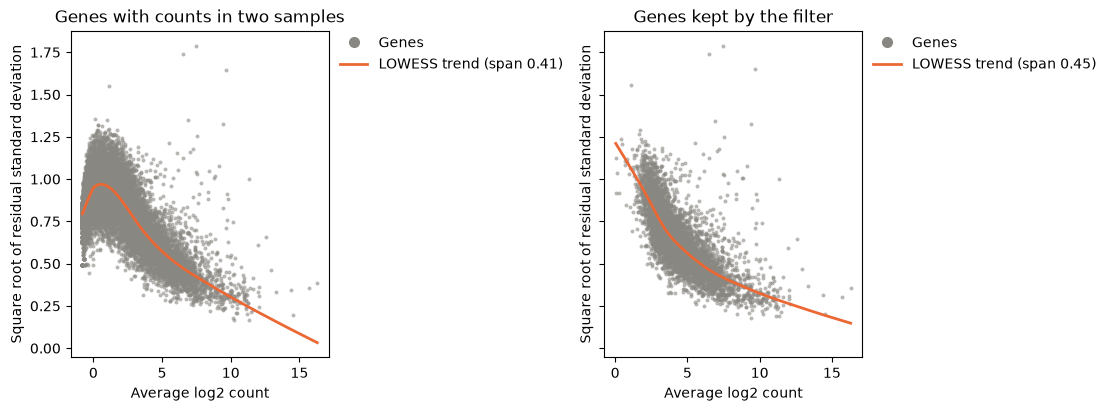

In [3]:
design = Design(
    kang.samples,
    "~ donor + condition",
    levels={"condition": ["ctrl", "stim"]},
    contrasts={"stim_vs_ctrl": "conditionstim"},
)
counts = kang.layer("counts", "CD14+ Monocytes")
detected = np.count_nonzero(counts, axis=0) >= 2
keep = filter_by_expression(counts, design=design)
by_condition = filter_by_expression(counts, sample_groups=kang.samples["condition"])
print(f"{detected.sum():>6,} genes with counts in at least two samples")
print(f"{keep.sum():>6,} kept by the filter with the paired design")
print(f"{by_condition.sum():>6,} kept by the filter with the condition as the group")

result = limma_voom(kang, design, groups="CD14+ Monocytes")
figure, (left, right) = plt.subplots(
    1, 2, figsize=(11, 4), layout="constrained", sharey=True
)
present = counts[:, detected]
plot_mean_variance(voom(present, design, norm_factors=tmm_factors(present)), ax=left)
left.set_title("Genes with counts in two samples")
plot_mean_variance(result, group="CD14+ Monocytes", ax=right)
right.set_title("Genes kept by the filter")
plt.show()

Without the filter, the trend falls at the low end, as the genes with mostly zero counts pull it down; with it, the trend falls steadily with the expression level, the shape voom expects. The number of samples a gene needs comes from the design's largest leverage: with the paired design, every sample's profile has a leverage of 9/16, so a gene needs enough counts in two samples; with the condition as the group, in eight, which keeps fewer genes.

## Normalization factors

Library sizes account for sequencing depth, not for composition: when a few genes take a larger share of a library, every other gene looks lower in it ([Library sizes and composition](../statistics/normalization_and_filtering.md#library-sizes)). TMM factors ({api}`tmm_factors`) rescale the libraries so that most genes do not change between samples [@robinson2010a]; here they are compared with the other rules ([Normalization factors and size factors](../statistics/normalization_and_filtering.md#normalization-and-size-factors)).


In [4]:
stimulated = np.asarray(kang.samples["condition"]) == "stim"
cpm = counts / counts.sum(axis=1, keepdims=True)
gain = cpm[stimulated].mean(axis=0) - cpm[~stimulated].mean(axis=0)
rising = np.argsort(gain)[-20:]
print(
    "The 20 genes that gain most take "
    f"{cpm[~stimulated][:, rising].sum(axis=1).mean():.0%} of the control libraries "
    f"and {cpm[stimulated][:, rising].sum(axis=1).mean():.0%} of the stimulated ones.\n"
)

kept = counts[:, keep]
library_sizes = kept.sum(axis=1)
deseq2 = median_ratio_size_factors(kept) / library_sizes
factors = {
    "TMM": tmm_factors(kept),
    "RLE": rle_factors(kept),
    "upper quartile": upper_quartile_factors(kept),
    "DESeq2": deseq2 / np.exp(np.mean(np.log(deseq2))),
}
print(f"{'median factor':<16}{'control':>9}{'stimulated':>12}")
for name, values in factors.items():
    print(
        f"{name:<16}{np.median(values[~stimulated]):>9.2f}"
        f"{np.median(values[stimulated]):>12.2f}"
    )

The 20 genes that gain most take 4% of the control libraries and 22% of the stimulated ones.

median factor     control  stimulated
TMM                  1.19        0.83
RLE                  1.19        0.84
upper quartile       1.06        0.93
DESeq2               1.19        0.84


Twenty genes that the stimulation raises take a fifth of the stimulated monocytes' reads, and the factors correct for it: TMM, RLE and DESeq2's size factors agree that the stimulated libraries count for about 0.83 of their size and the control ones about 1.19, so that without them most genes would look lower after the stimulation. The upper quartile, which scales each library by one quantile of its counts, corrects less.

## Genes with outlying variances

After voom, the residual variances of the genes should not depend on their expression, and empirical Bayes moderation shrinks each towards a common prior ([Empirical Bayes moderation](../statistics/empirical_bayes.md)). limma's `plotSA` ({api}`plot_residual_variances`) shows them, and `robust=True` estimates the prior so that genes with outlying variances do not distort it [@phipson2016] ([Estimating the prior](../statistics/empirical_bayes.md#estimating-the-prior)). {api}`DifferentialExpressionResult.fit` computes the fit of a cell type of a result again, from the cube and the design that the result keeps: a {api}`GroupFit`, with the samples, genes, values and weights fitted and the moderated tests, from which the figures of a result are drawn. Here it gives the prior degrees of freedom and the residual variances of the monocytes, moderated without and with `robust=True`.


prior degrees of freedom: 11.4, robust 27.7
largest residual variances: HBB, HBA2, HBA1, ISG15, CCL3, IFITM3, CCL2, CCL4, APOBEC3A, CXCL10, IFI6, LY6E


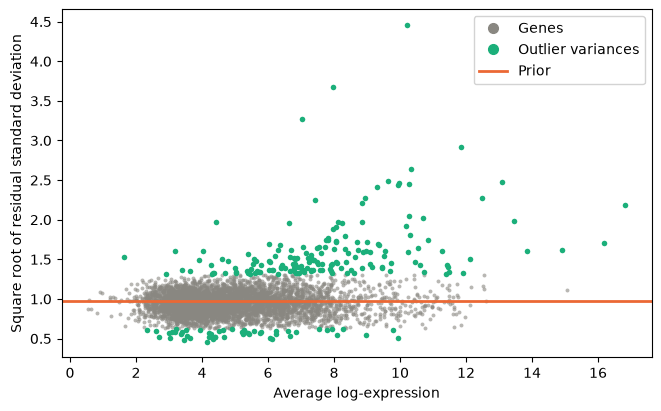

In [5]:
robust = limma_voom(kang, design, groups="CD14+ Monocytes", robust=True)
plain_fit = result.fit("CD14+ Monocytes")
robust_fit = robust.fit("CD14+ Monocytes")
print(
    f"prior degrees of freedom: {plain_fit.moderated.df_prior:.1f}, "
    f"robust {np.max(robust_fit.moderated.df_prior):.1f}"
)
symbols = plain_fit.features["symbol"]
largest = np.argsort(plain_fit.moderated.fit.sigma)[-12:][::-1]
print("largest residual variances:", ", ".join(symbols[largest]))
plot_residual_variances(robust, group="CD14+ Monocytes")
plt.show()

The genes with the largest variances are those of hemoglobin, whose reads come from red cells that contaminate some samples more than others, and interferon-stimulated genes and chemokines whose response differs between donors; the plot marks 217 outlying variances. Robust moderation gives such genes smaller prior degrees of freedom, so that their variances stay closer to their own estimates, and raises those of the other genes from 11.4 to 27.7, whose variances are then shrunk more, which gives their tests more power.

## A sample of poor quality

A sample that follows the model less closely than the others, such as a degraded one, adds noise to every gene. Sample quality weights estimate how closely each sample follows the model and down-weight it, instead of removing it [@liu2015]; [limma-voom and limma-trend](../statistics/limma_voom.md#sample-quality-weights) gives the model. In the simulated bulk experiment, sample `drug_b_3` has four times the dispersion of the others.


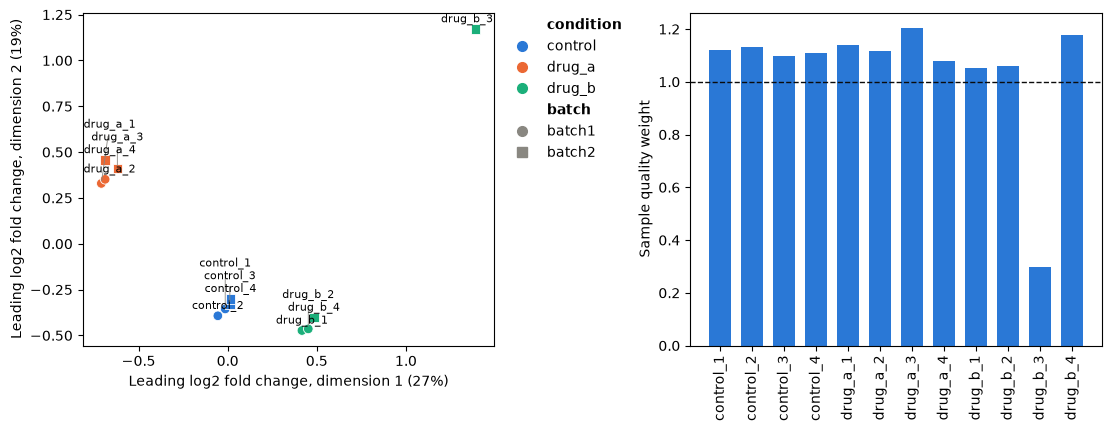

equal weights    192 genes called, 11 of them false
quality weights  204 genes called, 12 of them false


In [6]:
bulk = read_cube("simulated_bulk.cube.zarr")
truth = np.load("simulated_bulk_truth.npz")
bulk_design = Design(
    bulk.samples,
    "~ batch + condition",
    levels={"condition": ["control", "drug_a", "drug_b"]},
    contrasts={"drug_b_vs_control": "conditiondrug_b"},
)
equal = limma_voom(bulk, bulk_design)
weighted = limma_voom(bulk, bulk_design, quality_weights=True)

figure, (left, right) = plt.subplots(1, 2, figsize=(11, 4.2), layout="constrained")
plot_mds(bulk, color_by="condition", marker_by="batch", labels=True, ax=left)
plot_sample_weights(weighted, ax=right)
plt.show()

changed = set(bulk.features["feature_id"][truth["true_log2_fold_change_drug_b"] != 0])
for name, analysis in (("equal weights", equal), ("quality weights", weighted)):
    table = analysis.table()  # the one group and contrast
    called = table["feature_id"][table["adjusted_p_value"] < 0.05]
    true = sum(gene in changed for gene in called)
    print(f"{name:<16} {called.size} genes called, {called.size - true} of them false")

The noisy sample stands apart on the MDS plot and gets a weight of 0.30, while the others weigh slightly more than one, as the weights multiply to one. Down-weighting it finds more of the genes that drug B changes, with about the same number of false calls.

## Check the design

A label typed differently in one sample splits a group in two, and the analysis then runs without an error. {api}`Design.check` reports such problems, with what to do; here one stimulated sample is labelled `Stim`.


In [7]:
labels = list(kang.samples["condition"])
labels[5] = "Stim"
mislabelled = kang.samples.with_columns(condition=labels)
print(Design(mislabelled, "~ donor + condition").check())

Design check: 16 samples, 10 columns, rank 10, 6 residual degrees of freedom.
3 warnings:
  1. [similar_levels] condition has levels that differ only in case or
     surrounding spaces ('Stim' and 'stim'), and each is a group of its own; if
     they mean the same group, clean the labels before building the design
  2. [single_sample_level] condition has a single sample at level 'Stim'
     (1016_stim); effects of such a level rest on one sample with no replicate.
     Add replicates, merge the level with a similar one, or remove the sample
  3. [unreplicated_sample] the model fits sample 1016_ctrl (donor = 1016,
     condition = ctrl) exactly (leverage 1), so it tells nothing about the
     residual variance and the effects it determines rest on it alone. This
     happens when a level, or a combination of levels in an interaction, has too
     few samples for the terms that involve it; add replicates or simplify the
     formula


The check also finds aliased and confounded columns, levels without samples, contrasts the design cannot estimate and numeric codes that look like batches ([Design checks](../statistics/linear_models.md#design-checks)).

## Choices

- **The filter.** {api}`limma_voom` filters each cell type with its design, as above. `expression_filter` changes the thresholds, and `expression_filter={"sample_groups": "condition"}` groups the samples by a column instead, as {api}`filter_by_expression` does with `sample_groups=`, so that designs of the same samples test the same genes ([Filtering by expression](../statistics/normalization_and_filtering.md#filtering-by-expression)).
- **Normalization factors.** TMM by default, and `normalization=None` for library sizes alone. When a response changes many genes, check that the factors make sense, as above ([Normalization factors and size factors](../statistics/normalization_and_filtering.md#normalization-and-size-factors)).
- **Robust moderation.** Pass `robust=True` to {api}`limma_voom` when `plotSA` shows outlying variances, as here.
- **A poor sample.** Quality weights keep it at a lower weight; leaving it out loses its information, and in a paired design its partner's ([limma-voom and limma-trend](../statistics/limma_voom.md#sample-quality-weights)). `prior_weights="n_cells"` instead weights pseudobulk profiles by their number of cells; the two cannot be combined.
- **What to adjust for.** [Repeated measures and donors](repeated_measures.ipynb) partitions the variance of every gene among the variables of the design.
